# 03 – EDA and Feature Engineering
Exploring the cleaned data (214,253 listings) to find what drives used car prices, then creating features for modelling.

### Summary statistics
The median price is 12,995 and the mean is 17,169, so a few expensive cars pull the average up. The median car is from 2015 with about 110,000 miles. `cylinders` is still missing for about 29% of rows, which will be imputed during modelling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_parquet("../data/processed/vehicles_clean.parquet")
print(df.shape)
df[["price", "year", "odometer", "cylinders"]].describe().round(1)

(214253, 25)


,price,year,odometer,cylinders
count,214253.0,214253.0,214253.0,151854.0
mean,17169.0,2014.4,112978.0,5.7
std,14780.7,7.0,60182.7,1.6
min,500.0,1990.0,1.0,3.0
25%,6995.0,2011.0,71700.0,4.0
50%,12995.0,2015.0,110103.0,6.0
75%,22500.0,2019.0,149000.0,6.0
max,100000.0,2026.0,500000.0,12.0


### Price distribution
Most cars sell for 5,000–15,000, with a long tail up to 100,000, so price is right-skewed. After a log transform the distribution looks much closer to normal. I will test predicting log price, since many models work better with a less skewed target.

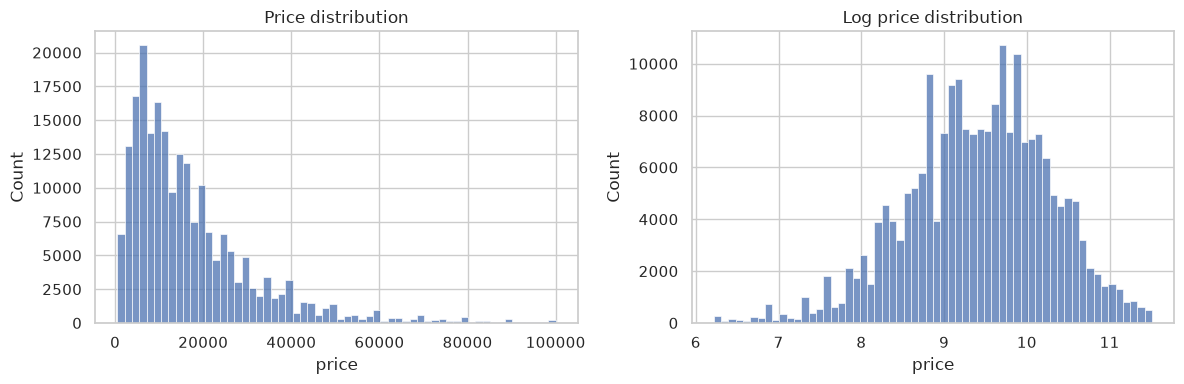

Skewness: 2.0 | log skewness: -0.36


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=ax[0])
ax[0].set_title("Price distribution")
sns.histplot(np.log1p(df["price"]), bins=60, ax=ax[1])
ax[1].set_title("Log price distribution")
plt.tight_layout()
plt.show()
print("Skewness:", df["price"].skew().round(2), "| log skewness:", np.log1p(df["price"]).skew().round(2))

### Price by manufacturer
Ram (about 24,000) and GMC (about 18,800) have the highest median prices, probably because they mostly sell trucks. Hyundai, Nissan and Kia are the cheapest. Luxury brands like BMW and Mercedes-Benz are not above Toyota or Ford, so brand alone does not separate expensive from cheap cars.

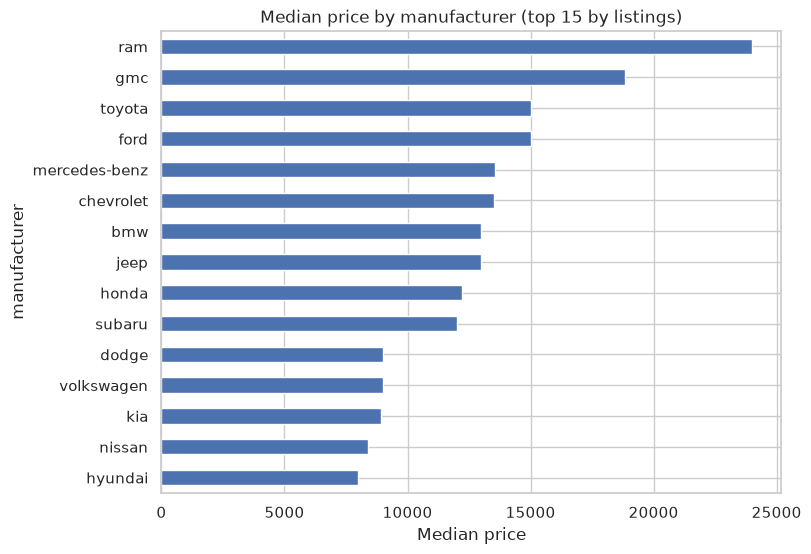

In [3]:
top = df["manufacturer"].value_counts().head(15).index
med = df[df["manufacturer"].isin(top)].groupby("manufacturer")["price"].median().sort_values()
med.plot(kind="barh", figsize=(8, 6), title="Median price by manufacturer (top 15 by listings)")
plt.xlabel("Median price")
plt.show()

### Age and mileage vs price
Newer cars are generally more expensive, and price drops as mileage rises, but the relationship is curved rather than a straight line. There is a large spread at every year, so other variables also matter. Based on this, I will create car age and a log of odometer as features.

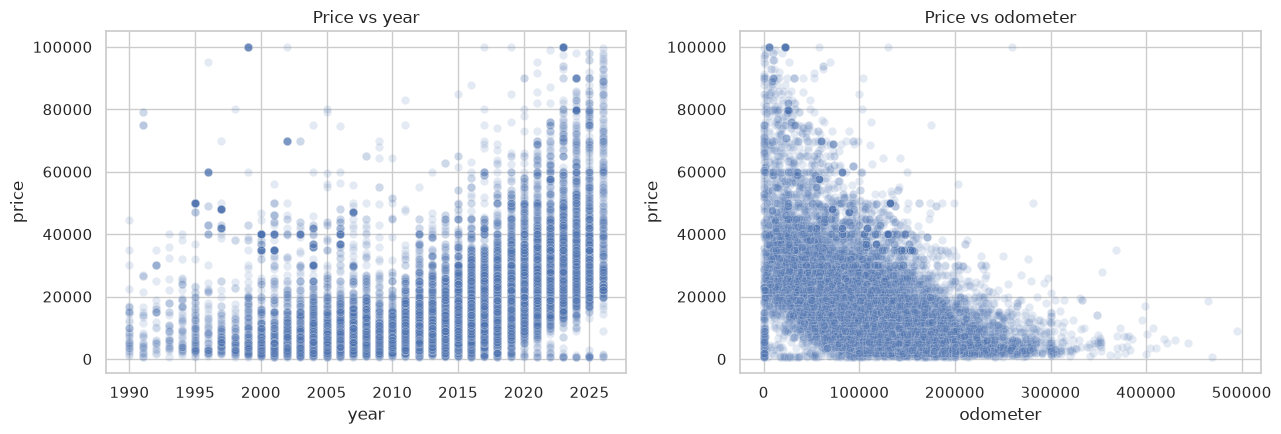

In [4]:
s = df.sample(20000, random_state=42)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=s, x="year", y="price", alpha=0.15, ax=ax[0])
ax[0].set_title("Price vs year")
sns.scatterplot(data=s, x="odometer", y="price", alpha=0.15, ax=ax[1])
ax[1].set_title("Price vs odometer")
plt.tight_layout()
plt.show()

### Categorical drivers
Condition follows the expected order from fair to new. Diesel and 4WD vehicles have the highest prices, probably because many are trucks. Cars with "unknown" condition or title status are priced like high-end cars, which suggests missing values are informative, likely from dealer listings. This supports keeping "unknown" as its own category instead of dropping those rows.

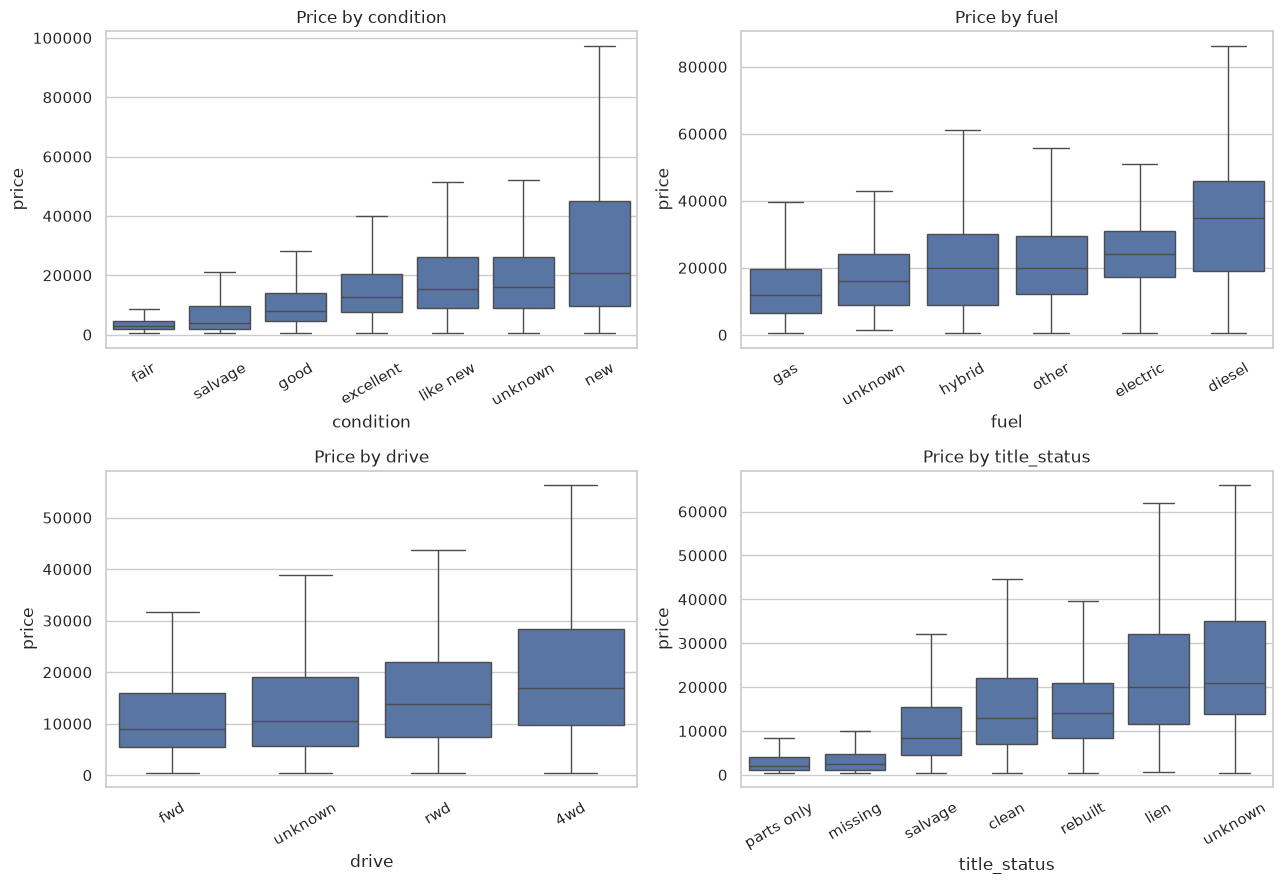

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, col in zip(ax.flat, ["condition", "fuel", "drive", "title_status"]):
    order = df.groupby(col)["price"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="price", order=order, showfliers=False, ax=a)
    a.set_title(f"Price by {col}")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Seller type and state
Dealer listings have a median price of 15,695 compared with 7,300 for private owners, so seller type clearly matters (155,003 dealer vs 59,250 owner listings). The most expensive states by median are Wyoming, Utah, Hawaii and Alaska, but these may rest on few listings, so I will check the counts before treating location as a strong signal.

              count   median     mean
seller_type                          
dealer       155003  15695.0  19589.0
owner         59250   7300.0  10839.0


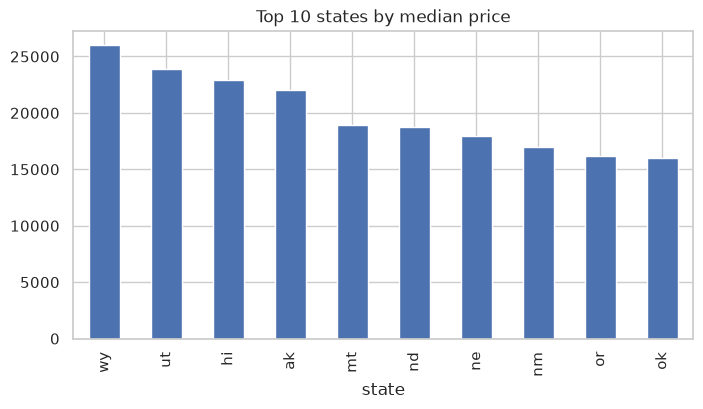

In [6]:
print(df.groupby("seller_type")["price"].agg(["count", "median", "mean"]).round(0))
df.groupby("state")["price"].median().sort_values(ascending=False).head(10).plot(
    kind="bar", title="Top 10 states by median price", figsize=(8, 4))
plt.show()

### Feature engineering
I created car age (posting year minus model year), miles per year, log odometer, a luxury brand flag, a has-VIN flag, description length and posting month. Log price has skewness of -0.36 compared with 2.0 for raw price, so I will model log price. Correlation with log price: car age -0.50, log odometer -0.39, has VIN 0.36 and description length 0.36. Miles per year (0.02), luxury flag (0.03) and posting month (-0.06) are almost uncorrelated, so they add little on their own.

In [7]:
fe = df.copy()
posting_year = fe["posting_date"].dt.year

# Age of the car at posting time
fe["car_age"] = (posting_year - fe["year"]).clip(lower=0)
# Average yearly mileage (+1 avoids dividing by zero for new cars)
fe["miles_per_year"] = fe["odometer"] / (fe["car_age"] + 1)
# Log of odometer reduces skew
fe["log_odometer"] = np.log1p(fe["odometer"])
# Luxury brand flag
luxury = ["bmw", "mercedes-benz", "audi", "lexus", "porsche", "jaguar", "land rover",
          "cadillac", "tesla", "infiniti", "acura", "volvo", "lincoln", "maserati"]
fe["is_luxury"] = fe["manufacturer"].isin(luxury).astype(int)
# Listing-quality signals
fe["has_vin"] = fe["VIN"].notna().astype(int)
fe["description_length"] = fe["description"].fillna("").str.len()
fe["posting_month"] = fe["posting_date"].dt.month
# Log of target (useful for modelling)
fe["log_price"] = np.log1p(fe["price"])

new = ["car_age", "miles_per_year", "log_odometer", "is_luxury", "has_vin",
       "description_length", "posting_month"]
print(fe[new + ["log_price"]].corr()["log_price"].drop("log_price").round(3).sort_values())

car_age              -0.502
log_odometer         -0.390
posting_month        -0.062
miles_per_year        0.015
is_luxury             0.030
description_length    0.355
has_vin               0.357
Name: log_price, dtype: float64


### Correlation heatmap
Odometer (-0.53) and year (0.43) have the strongest links with price. Car age and year have a correlation of -1.00, so they carry the same information and I will keep only one in the models. Has VIN and description length are moderately related to price (0.28 and 0.33) and to each other (0.46), probably because dealers write longer listings and include VINs. Since a user cannot easily enter these in an app, I will leave them out of the final model.

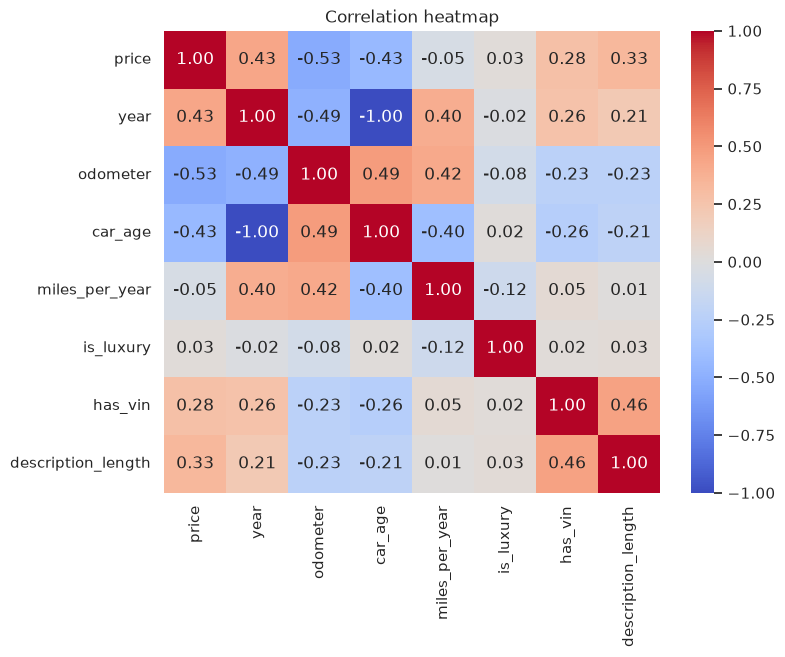

Saved: (214253, 33)


In [8]:
num = fe[["price", "year", "odometer", "car_age", "miles_per_year", "is_luxury",
          "has_vin", "description_length"]].astype(float)
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

fe.to_parquet("../data/processed/vehicles_features.parquet", index=False)
print("Saved:", fe.shape)

## Summary
Price is driven mainly by year, mileage, seller type, condition and fuel/drive type. Several engineered features (luxury flag, miles per year) added little, which I will state honestly in the report. The features are saved for modelling.